In [1]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm

logging.getLogger("pymc").setLevel(logging.WARNING)


In [2]:
data = pd.read_csv("data/howell1.csv", sep=";")
data = data[data.age >= 18]

In [3]:
data_w = data["weight"].to_numpy()
data_h = data["height"].to_numpy()

with pm.Model() as model:
    # priors
    a = pm.Normal("a", mu=178, sigma=20)
    b = pm.LogNormal("b", mu=0, sigma=1)
    s = pm.Uniform("s", lower=0, upper=50)

    # data
    w = pm.Data("w", data_w)

    # linear model
    u = a + b * (w - data_w.mean())

    # likelihood
    pm.Normal("h", mu=u, sigma=s, observed=data_h, shape=w.shape)

    # samples
    sample_a, sample_b, sample_s = pm.draw([a, b, s], draws=10_000)
    posterior = pm.sample(10_000, quiet=True)
    sample_h = pm.sample_posterior_predictive(posterior, predictions=True, progressbar=False)


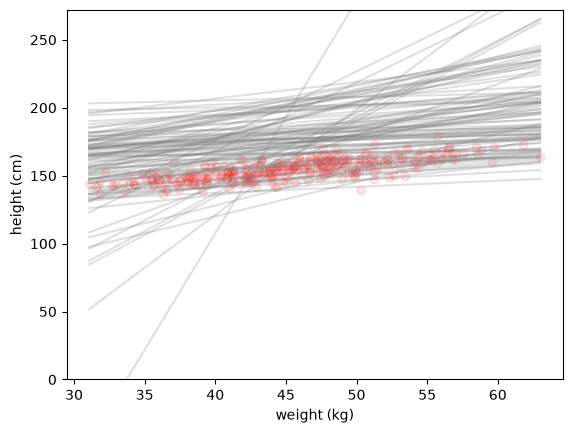

In [4]:
# prior simulation
plt.xlabel("weight (kg)")
plt.ylabel("height (cm)")

plt.ylim(0, 272)

x = np.linspace(data_w.min(), data_w.max(), 100)
for ai, bi in zip(sample_a[:100], sample_b):
    ui = ai + bi * (x - data_w.mean())
    plt.plot(x, ui, color="gray", alpha=0.25)

plt.scatter(data_w, data_h, color="red", alpha=0.1);


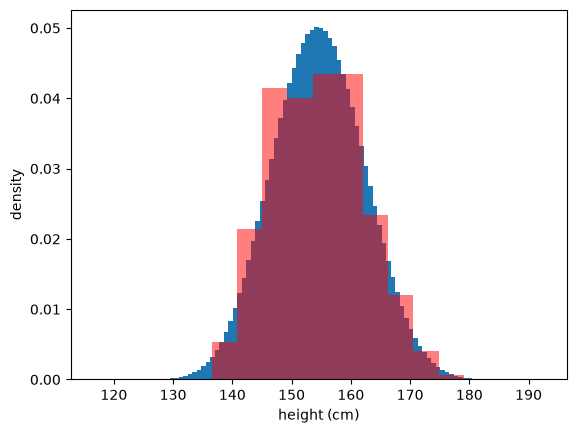

In [5]:
# posterior samples
plt.xlabel("height (cm)")
plt.ylabel("density")
plt.hist(sample_h.predictions.h.values.flatten(), bins=100, density=True)
plt.hist(data_h, density=True, color="red", alpha=0.5);


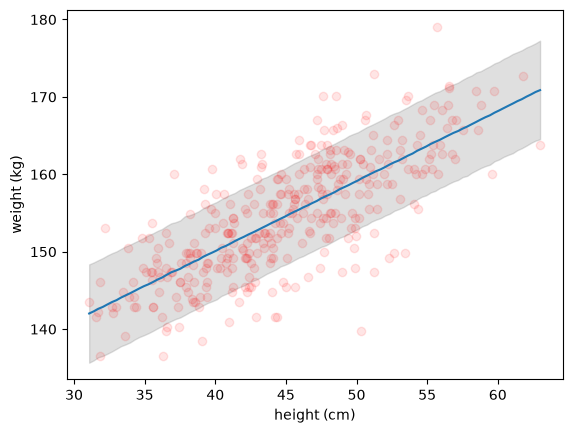

In [ ]:
# 89% credible interval for weight range
x = np.linspace(data_w.min(), data_w.max(), 100)
with model:
    pm.set_data(dict(w=x))
    sample_h2 = pm.sample_posterior_predictive(posterior, predictions=True, progressbar=False)

h_x = sample_h2.predictions.h.values.reshape(-1, len(x))
mid = h_x.mean(axis=0)
lo, hi = np.percentile(h_x, [11, 89], axis=0)

plt.xlabel("height (cm)")
plt.ylabel("weight (kg)")

plt.fill_between(x, lo, hi, color="gray", alpha=0.25)
plt.plot(x, mid)

plt.scatter(data_w, data_h, color="red", alpha=0.1);
